# Assignment 2 — Questions 1 and 2

This notebook maps the supplied state obesity values and explores city elevations using a Voronoi-style partition with a smoothed surface.

**Run from top to bottom.** Q1 uses the local files in `US_Data/` and `other/`. Q2 downloads the GeoNames U.S. gazetteer from the public source below, so it requires an internet connection the first time it runs.

## Data and method notes
- **Q1:** The obesity table is joined to the Census state-boundary shapefile using state names. The map shows the 50 states; the District of Columbia and Puerto Rico are excluded because they are not states. The supplied table does not identify a measurement year, so no year is inferred.
- **Q2:** City/place elevations come from GeoNames' `dem` field (meters, derived from elevation models). Places with population of at least 25,000 are used. The analysis is limited to the contiguous 48 states so the interpolation is legible and not distorted by the distance to Alaska or Hawaii.
- **Smoothing:** Each grid cell first receives the elevation of its nearest city/place, creating Voronoi regions. A normalized Gaussian filter then smooths the boundaries between those regions. This is an interpolation, not a claim that elevation was measured at every location.

In [1]:
from pathlib import Path
from io import BytesIO
import zipfile
import urllib.request

import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter
from scipy.spatial import cKDTree

plt.rcParams.update({"figure.dpi": 120, "axes.titlesize": 13, "axes.titleweight": "bold"})

# Resolve paths whether the notebook is run from the workspace root or its parent.
BASE_DIR = Path.cwd()
if not (BASE_DIR / "US_Data" / "us_state.shp").exists():
    BASE_DIR = BASE_DIR.parent

STATE_SHP = BASE_DIR / "US_Data" / "us_state.shp"
OBESITY_CSV = BASE_DIR / "other" / "National_Obesity_By_State.csv"
assert STATE_SHP.exists(), f"State boundary file not found: {STATE_SHP}"
assert OBESITY_CSV.exists(), f"Obesity table not found: {OBESITY_CSV}"
print(f"Workspace data found under: {BASE_DIR}")

Workspace data found under: c:\Users\LG\OneDrive - Luleå University of Technology\LTU\data visualizaiton\code\assign2\actual cod


## Q1 — Obesity by U.S. state

The choropleth encodes the supplied `Obesity` values. The thick outlines and summary labels identify the highest and lowest state values.

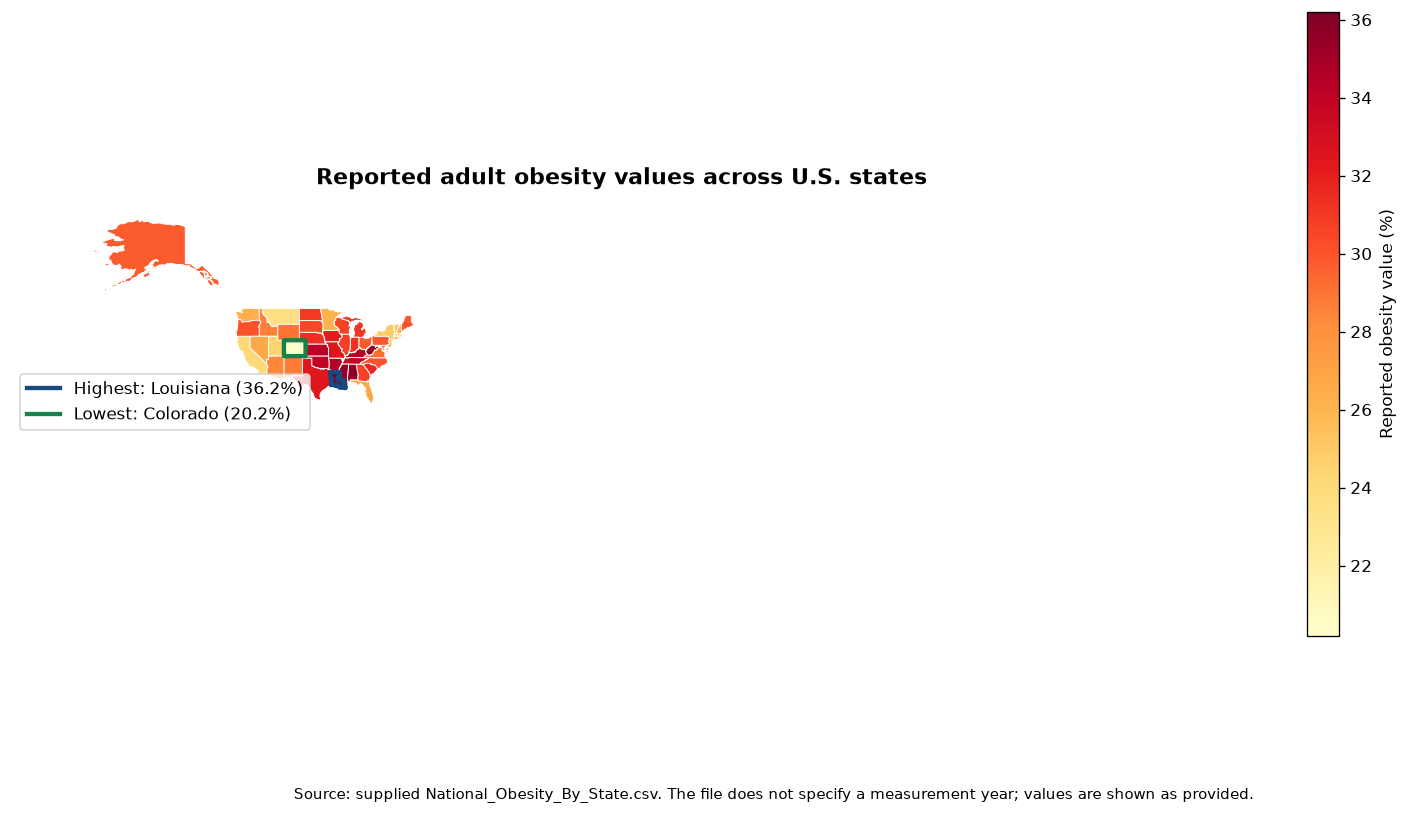

Highest reported value: Louisiana — 36.2%
Lowest reported value:  Colorado — 20.2%


In [2]:
states = gpd.read_file(STATE_SHP)
obesity = pd.read_csv(OBESITY_CSV)

required_fields = {"NAME", "Obesity"}
if not required_fields.issubset(obesity.columns):
    raise ValueError(f"Obesity CSV must contain {sorted(required_fields)}")
if "NAME" not in states.columns:
    raise ValueError("State shapefile must contain a NAME field for the join")
if states["NAME"].duplicated().any() or obesity["NAME"].duplicated().any():
    raise ValueError("Expected one row per state name in both input files")

map_data = states.merge(
    obesity[["NAME", "Obesity"]], on="NAME", how="inner", validate="one_to_one"
)
map_data["Obesity"] = pd.to_numeric(map_data["Obesity"], errors="coerce")
map_data = map_data.dropna(subset=["Obesity"])
map_data = map_data.loc[~map_data["NAME"].isin(["District of Columbia", "Puerto Rico"])].copy()

if len(map_data) != 50:
    raise ValueError(f"Expected 50 state polygons after joining; found {len(map_data)}")

highest = map_data.loc[map_data["Obesity"].idxmax()]
lowest = map_data.loc[map_data["Obesity"].idxmin()]

fig, ax = plt.subplots(figsize=(13, 8))
map_data.plot(
    column="Obesity", cmap="YlOrRd", linewidth=0.55, edgecolor="white",
    legend=True, legend_kwds={"label": "Reported obesity value (%)", "shrink": 0.72},
    ax=ax, missing_kwds={"color": "lightgrey"}
)
map_data.loc[[highest.name]].plot(ax=ax, facecolor="none", edgecolor="#174a7e", linewidth=2.6)
map_data.loc[[lowest.name]].plot(ax=ax, facecolor="none", edgecolor="#16824b", linewidth=2.6)

ax.set_title("Reported adult obesity values across U.S. states", pad=15)
ax.set_axis_off()
ax.legend(
    handles=[
        Line2D([0], [0], color="#174a7e", lw=2.6, label=f"Highest: {highest['NAME']} ({highest['Obesity']:.1f}%)"),
        Line2D([0], [0], color="#16824b", lw=2.6, label=f"Lowest: {lowest['NAME']} ({lowest['Obesity']:.1f}%)"),
    ], loc="lower left", frameon=True
)
fig.text(
    0.5, 0.035,
    "Source: supplied National_Obesity_By_State.csv. The file does not specify a measurement year; values are shown as provided.",
    ha="center", fontsize=9
)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

print(f"Highest reported value: {highest['NAME']} — {highest['Obesity']:.1f}%")
print(f"Lowest reported value:  {lowest['NAME']} — {lowest['Obesity']:.1f}%")

### Q1 — Context

Darker shading represents higher reported values. Compare the highlighted extremes with neighboring states to see whether high or low values form regional clusters. The supplied CSV does not state its year or methodology, so treat this as a map of the provided values rather than a time-specific or causal conclusion.

## Q2 — Voronoi regions and smoothed city elevations

GeoNames provides the point locations and DEM elevation estimates. The left panel shows nearest-place Voronoi regions; the right panel applies normalized Gaussian smoothing to the same elevation field. Both panels are masked to the contiguous-state boundaries.

In [3]:
# GeoNames US.zip schema: https://www.geonames.org/export/ (19 tab-separated columns).
# Attribution: GeoNames, https://www.geonames.org/ (CC BY 4.0).
GEONAMES_URL = "https://download.geonames.org/export/dump/US.zip"
columns = [
    "geonameid", "name", "asciiname", "alternatenames", "latitude", "longitude",
    "feature_class", "feature_code", "country_code", "cc2", "admin1_code",
    "admin2_code", "admin3_code", "admin4_code", "population", "elevation",
    "dem", "timezone", "modification_date",
]

with urllib.request.urlopen(GEONAMES_URL, timeout=60) as response:
    archive_bytes = response.read()

with zipfile.ZipFile(BytesIO(archive_bytes)) as archive:
    data_member = next(name for name in archive.namelist() if name.endswith("US.txt"))
    with archive.open(data_member) as data_file:
        places = pd.read_csv(data_file, sep="\t", header=None, names=columns, low_memory=False)

for field in ["latitude", "longitude", "population", "dem"]:
    places[field] = pd.to_numeric(places[field], errors="coerce")

city_samples = places.loc[
    places["country_code"].eq("US")
    & places["feature_class"].eq("P")
    & places["population"].ge(25_000)
    & places["dem"].between(-500, 9_000)
].copy()

print(f"GeoNames places downloaded: {len(places):,}")
print(f"Populated-place elevation samples (population >= 25,000): {len(city_samples):,}")
if city_samples.empty:
    raise ValueError("No GeoNames places remain after the population/elevation filters")

GeoNames places downloaded: 2,241,458
Populated-place elevation samples (population >= 25,000): 2,083


In [4]:
# Project to a meter-based equal-area CRS before distance-based interpolation.
contiguous_exclusions = {"Alaska", "Hawaii", "Puerto Rico", "District of Columbia"}
contiguous = states.loc[~states["NAME"].isin(contiguous_exclusions)].to_crs("EPSG:5070")
land = contiguous.geometry.unary_union

city_points = gpd.GeoDataFrame(
    city_samples,
    geometry=gpd.points_from_xy(city_samples["longitude"], city_samples["latitude"]),
    crs="EPSG:4326",
).to_crs("EPSG:5070")
# Keep only sample points inside the contiguous-state polygons.
city_points = city_points.loc[city_points.geometry.apply(land.covers)].copy()
if len(city_points) < 3:
    raise ValueError(f"Too few in-boundary city samples for interpolation: {len(city_points)}")

elevations = city_points["dem"].to_numpy(dtype=float)
coordinates = np.column_stack([city_points.geometry.x, city_points.geometry.y])
min_x, min_y, max_x, max_y = contiguous.total_bounds

# A 420 x 250 grid defines the raster; nearest sample values form Voronoi regions.
nx, ny = 420, 250
x_grid = np.linspace(min_x, max_x, nx)
y_grid = np.linspace(min_y, max_y, ny)
grid_x, grid_y = np.meshgrid(x_grid, y_grid)
tree = cKDTree(coordinates)
_, nearest_index = tree.query(np.column_stack([grid_x.ravel(), grid_y.ravel()]), k=1)
voronoi_elevation = elevations[nearest_index].reshape(ny, nx)

# Mask to the contiguous U.S. polygon. Shapely 2 is vectorized; the fallback
# keeps the notebook usable with older Shapely installations.
import shapely
if hasattr(shapely, "contains_xy"):
    inside = shapely.contains_xy(land, grid_x, grid_y)
else:
    from shapely.geometry import Point
    inside = np.fromiter(
        (land.covers(Point(x, y)) for x, y in zip(grid_x.ravel(), grid_y.ravel())),
        dtype=bool, count=grid_x.size
    ).reshape(grid_x.shape)

voronoi_elevation[~inside] = np.nan

# Normalized convolution prevents the Gaussian filter from biasing coastlines
# toward zero where the raster is masked outside the land boundary.
sigma_cells = 2.0
valid = inside.astype(float)
smoothed_numerator = gaussian_filter(np.where(inside, voronoi_elevation, 0.0), sigma=sigma_cells)
smoothed_denominator = gaussian_filter(valid, sigma=sigma_cells)
smoothed_elevation = smoothed_numerator / np.maximum(smoothed_denominator, 1e-12)
smoothed_elevation[~inside] = np.nan

print(f"Contiguous-U.S. sample points used: {len(city_points):,}")
print(f"Gaussian smoothing: sigma={sigma_cells} grid cells; projection: EPSG:5070 (meters)")

C:\Users\LG\AppData\Local\Temp\ipykernel_10516\2726707695.py:4: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  land = contiguous.geometry.unary_union


Contiguous-U.S. sample points used: 2,055
Gaussian smoothing: sigma=2.0 grid cells; projection: EPSG:5070 (meters)


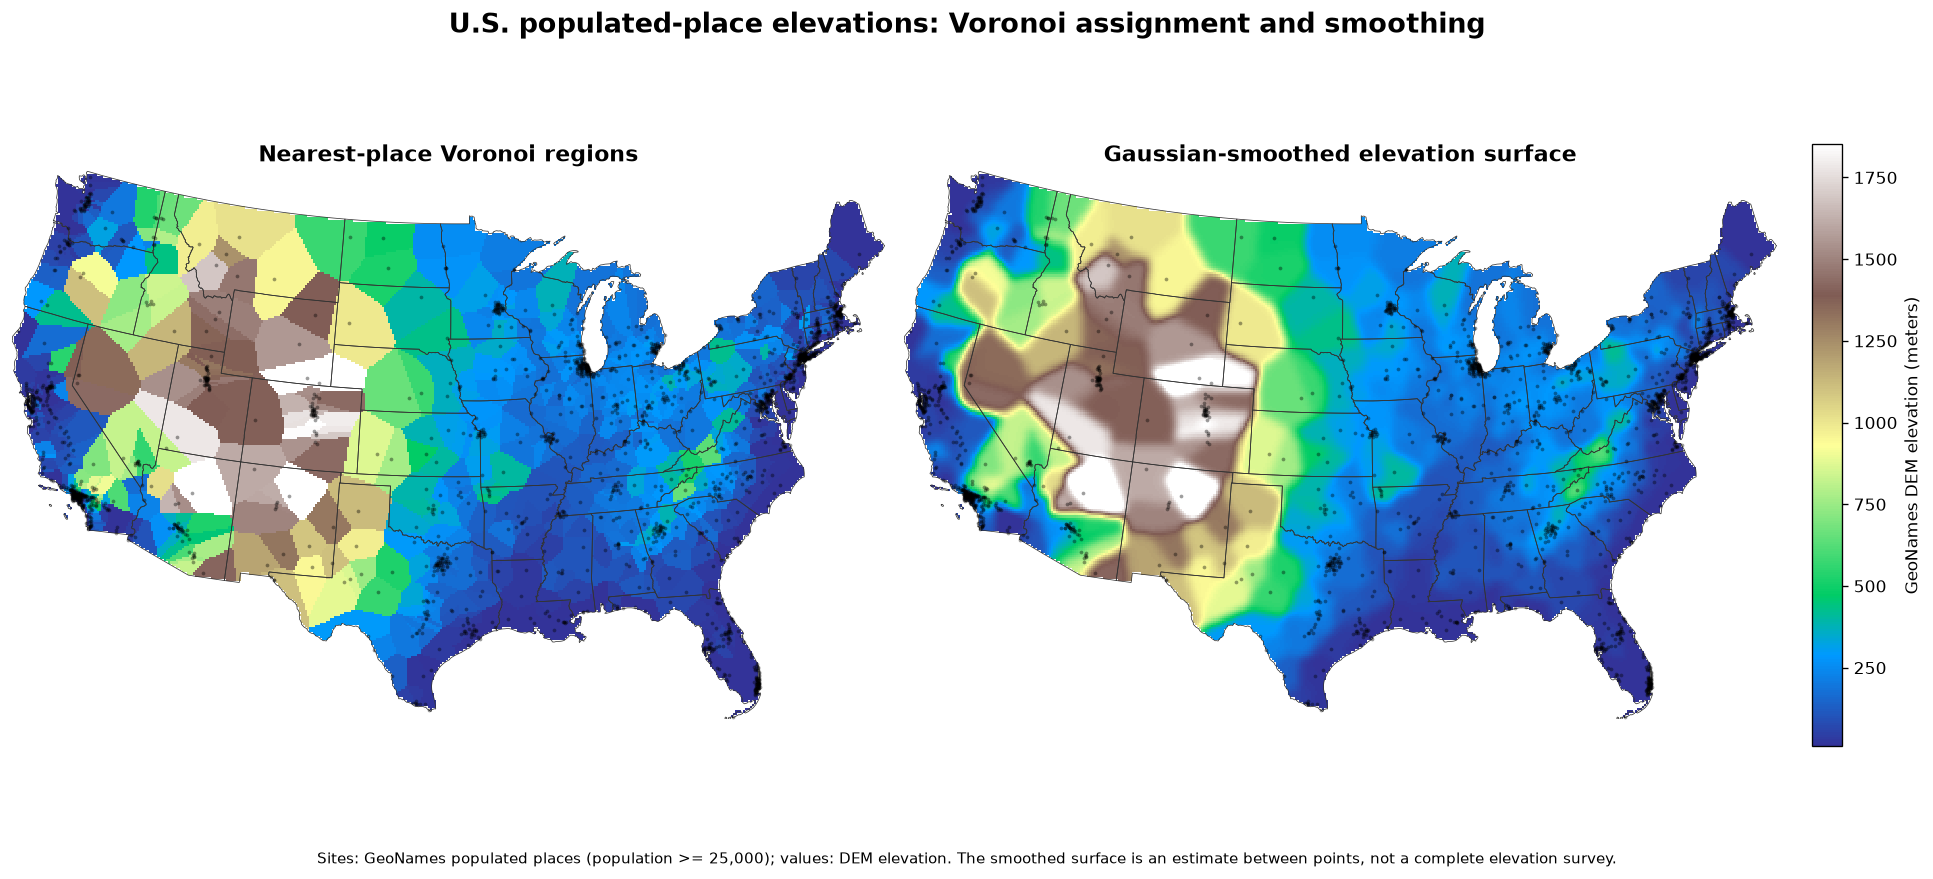

In [5]:
vmin = np.nanpercentile(smoothed_elevation, 2)
vmax = np.nanpercentile(smoothed_elevation, 98)
extent = [min_x, max_x, min_y, max_y]
fig, axes = plt.subplots(1, 2, figsize=(16, 7), constrained_layout=True)

panels = [
    (voronoi_elevation, "Nearest-place Voronoi regions"),
    (smoothed_elevation, "Gaussian-smoothed elevation surface"),
]
for ax, (surface, title) in zip(axes, panels):
    image = ax.imshow(
        np.ma.masked_invalid(surface), origin="lower", extent=extent,
        cmap="terrain", vmin=vmin, vmax=vmax, interpolation="nearest", zorder=1
    )
    contiguous.boundary.plot(ax=ax, color="#333333", linewidth=0.45, zorder=2)
    ax.scatter(
        city_points.geometry.x, city_points.geometry.y,
        s=5, c="black", alpha=0.38, linewidths=0, zorder=3
    )
    ax.set_title(title)
    ax.set_xlim(min_x, max_x)
    ax.set_ylim(min_y, max_y)
    ax.set_aspect("equal")
    ax.set_axis_off()

colorbar = fig.colorbar(image, ax=axes, shrink=0.76, pad=0.02)
colorbar.set_label("GeoNames DEM elevation (meters)")
fig.suptitle("U.S. populated-place elevations: Voronoi assignment and smoothing", fontsize=16, fontweight="bold")
fig.text(
    0.5, -0.02,
    "Sites: GeoNames populated places (population >= 25,000); values: DEM elevation. "
    "The smoothed surface is an estimate between points, not a complete elevation survey.",
    ha="center", fontsize=9
)
plt.show()

### Q2 — Context and limitations

The unsmoothed panel assigns each location the DEM value of its nearest sampled place, creating Voronoi-like regions. The Gaussian-filtered panel softens abrupt transitions between those regions. Broad high-elevation areas in the West and lower elevations across much of the central and eastern U.S. are visible, but sample density is uneven and smaller high/low features are blurred by smoothing. Only places with population at least 25,000 are sampled, and GeoNames DEM values are model-derived rather than direct measurements at every city. Source: [GeoNames U.S. download](https://download.geonames.org/export/dump/US.zip), [GeoNames](https://www.geonames.org/), CC BY 4.0.